<a href="https://colab.research.google.com/github/birajsingh08/Network-Intrusion-Detection/blob/main/Network_Intrusion_Detection_GA_MLP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



```
Team 16:
Biraj Kumar Singh-RA2311003011115
Aakash B-RA2311003010102
```







**Dataset:** UNSW-NB15 raw CSV parts (`UNSW-NB15_1.csv` through `_4.csv`)  
**Model:** Genetic Algorithm (GA) feature selection + Neural Network (MLP)  
**Task:** Binary classification — `0 = Normal`, `1 = Suspicious/Attack`

> The four raw CSV parts do not include headers. This notebook assigns the official 49-column schema. The full dataset is large, so the notebook defaults to a configurable sample for a hackathon-friendly run. Set `MAX_ROWS = 0` to use all records (may take much longer and require more RAM).



In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
# Configuration

import os
import pandas as pd

# Folder shown in your Google Drive screenshot
DATA_DIR = "/content/drive/MyDrive/CSV Files"

# UNSW-NB15 dataset files
PART_FILES = [
    os.path.join(DATA_DIR, "UNSW-NB15_1.csv"),
    os.path.join(DATA_DIR, "UNSW-NB15_2.csv"),
    os.path.join(DATA_DIR, "UNSW-NB15_3.csv"),
    os.path.join(DATA_DIR, "UNSW-NB15_4.csv")
]

# Verify the files exist
for file in PART_FILES:
    print(file, "->", os.path.exists(file))

# Load all four CSV files
dfs = [pd.read_csv(file, low_memory=False) for file in PART_FILES]

# Combine into one dataset
df = pd.concat(dfs, ignore_index=True)

print("\nDataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())


# Use a manageable sample for the hackathon demo.
# Set MAX_ROWS = 0 to load every row (can need substantial RAM/time).
MAX_ROWS = 120_000
TEST_SIZE = 0.20
RANDOM_STATE = 42

!pip -q install scikit-learn joblib


/content/drive/MyDrive/CSV Files/UNSW-NB15_1.csv -> True
/content/drive/MyDrive/CSV Files/UNSW-NB15_2.csv -> True
/content/drive/MyDrive/CSV Files/UNSW-NB15_3.csv -> True
/content/drive/MyDrive/CSV Files/UNSW-NB15_4.csv -> True

Dataset loaded successfully!
Shape: (2540043, 139)


,59.166.0.0,1390,149.171.126.6,53,udp,CON,0.001055,132,164,31,...,456.043567,15.530109,1424250009,1424250009.1,3.943843,4.912488,0.00059,0.000473,0.000117,4
0,59.166.0.0,33661,149.171.126.9,1024,udp,CON,0.036133,528.0,304.0,31,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,59.166.0.6,1464,149.171.126.7,53,udp,CON,0.001119,146.0,178.0,31,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,59.166.0.5,3593,149.171.126.5,53,udp,CON,0.001209,132.0,164.0,31,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,59.166.0.3,49664,149.171.126.0,53,udp,CON,0.001169,146.0,178.0,31,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,59.166.0.0,32119,149.171.126.9,111,udp,CON,0.078339,568.0,312.0,31,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
import os, gc, time, warnings, joblib
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import mutual_info_classif
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

# Official UNSW-NB15 49-column schema for the raw CSV parts (which have no header row).
COLUMNS = [
    "srcip", "sport", "dstip", "dsport", "proto", "state", "dur", "sbytes",
    "dbytes", "sttl", "dttl", "sloss", "dloss", "service", "Sload", "Dload",
    "Spkts", "Dpkts", "swin", "dwin", "stcpb", "dtcpb", "smeansz", "dmeansz",
    "trans_depth", "res_bdy_len", "Sjit", "Djit", "Stime", "Ltime", "Sintpkt",
    "Dintpkt", "tcprtt", "synack", "ackdat", "is_sm_ips_ports", "ct_state_ttl",
    "ct_flw_http_mthd", "is_ftp_login", "ct_ftp_cmd", "ct_srv_src", "ct_srv_dst",
    "ct_dst_ltm", "ct_src_ltm", "ct_src_dport_ltm", "ct_dst_sport_ltm",
    "ct_dst_src_ltm", "attack_cat", "Label"
]
assert len(COLUMNS) == 49
print("Schema ready:", len(COLUMNS), "columns")


Schema ready: 49 columns


In [ ]:
# Read the four headerless CSV files. Keep only a random sample if MAX_ROWS is set.
# Read in chunks to avoid loading all ~580 MB at once.
def load_unsw_parts(files, max_rows=120_000, chunksize=50_000):
    chunks = []
    rows_kept = 0
    for path in files:
        if not os.path.exists(path):
            raise FileNotFoundError(
                f"Missing file: {path}\nUpload all four CSV parts to the Drive folder configured in DATA_DIR."
            )
        print("Reading:", os.path.basename(path))
        for chunk in pd.read_csv(
            path, header=None, names=COLUMNS, chunksize=chunksize,
            low_memory=False, encoding="latin1"
        ):
            # Label is the last column; convert to numeric binary target.
            chunk["Label"] = pd.to_numeric(chunk["Label"], errors="coerce")
            chunk = chunk.dropna(subset=["Label"])
            if max_rows and max_rows > 0:
                remaining = max_rows - rows_kept
                if remaining <= 0:
                    break
                # Sampling from each chunk avoids always taking only the first rows.
                take = min(remaining, max(1, int(chunksize * max_rows / 2_500_000)))
                if len(chunk) > take:
                    chunk = chunk.sample(n=take, random_state=RANDOM_STATE + rows_kept)
            chunks.append(chunk)
            rows_kept += len(chunk)
            if max_rows and rows_kept >= max_rows:
                break
        if max_rows and rows_kept >= max_rows:
            break
    data = pd.concat(chunks, ignore_index=True)
    if max_rows and len(data) > max_rows:
        data = data.sample(n=max_rows, random_state=RANDOM_STATE).reset_index(drop=True)
    return data

data = load_unsw_parts(PART_FILES, MAX_ROWS)
print("Loaded shape:", data.shape)
display(data.head())
print("\nLabel counts (0=Normal, 1=Attack):")
display(data["Label"].value_counts().sort_index())


Reading: UNSW-NB15_1.csv
Reading: UNSW-NB15_2.csv
Reading: UNSW-NB15_3.csv
Reading: UNSW-NB15_4.csv
Loaded shape: (120000, 49)


,srcip,sport,dstip,dsport,proto,state,dur,sbytes,dbytes,sttl,...,ct_ftp_cmd,ct_srv_src,ct_srv_dst,ct_dst_ltm,ct_src_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,attack_cat,Label
0,59.166.0.3,50234,149.171.126.4,111,udp,CON,0.008102,568,320,31,...,0,7,7,2,2,1,1,2,NaN,0
1,59.166.0.5,29850,149.171.126.3,5190,tcp,FIN,0.004456,1470,1728,31,...,0,3,5,1,3,1,1,1,NaN,0
2,59.166.0.2,49540,149.171.126.7,53,udp,CON,0.001116,132,164,31,...,0,8,6,1,1,1,1,1,NaN,0
3,59.166.0.7,5857,149.171.126.1,6881,tcp,FIN,0.018618,1540,1644,31,...,0,7,2,1,1,1,1,1,NaN,0
4,59.166.0.6,58887,149.171.126.8,25,tcp,FIN,0.021377,37152,3276,31,...,0,1,1,1,4,1,1,1,NaN,0



Label counts (0=Normal, 1=Attack):


,count
Label,
0,104863
1,15137


## Preprocessing

- `Label` is the binary target (`0` normal, `1` attack).
- `attack_cat` is removed because it directly reveals the attack type and would leak target information.
- Source/destination IP addresses and timestamps are dropped to reduce identifier leakage.
- Categorical values are one-hot encoded; numeric values are imputed and standardized.


In [ ]:
# Create binary target and remove leakage/identifier columns.
y = data["Label"].astype(int).replace({0: 0})
y = (y != 0).astype(int)
X = data.drop(columns=["Label", "attack_cat", "srcip", "dstip", "Stime", "Ltime"], errors="ignore")

# Convert columns that should be numeric, while preserving true categorical columns.
for col in X.columns:
    if X[col].dtype == "object":
        # Numeric-looking columns can arrive as strings in imperfect CSV rows.
        converted = pd.to_numeric(X[col], errors="coerce")
        if converted.notna().mean() > 0.95:
            X[col] = converted

categorical_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
numeric_cols = [c for c in X.columns if c not in categorical_cols]

print("Rows:", len(X))
print("Raw input features:", X.shape[1])
print("Numeric:", len(numeric_cols), "| Categorical:", len(categorical_cols))
print("Target distribution:")
display(y.value_counts().rename(index={0:"Normal", 1:"Suspicious"}))


Rows: 120000
Raw input features: 43
Numeric: 39 | Categorical: 4
Target distribution:


,count
Label,
Normal,104863
Suspicious,15137


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)

# 2. Clean numeric columns
for col in numeric_cols:
    X_train[col] = pd.to_numeric(X_train[col], errors="coerce")
    X_test[col] = pd.to_numeric(X_test[col], errors="coerce")

# 3. Convert categorical values to consistent strings
# Preserve missing values for the imputer
for col in categorical_cols:
    X_train[col] = X_train[col].map(
        lambda v: str(v) if pd.notna(v) else np.nan
    )
    X_test[col] = X_test[col].map(
        lambda v: str(v) if pd.notna(v) else np.nan
    )

# 4. Build preprocessing pipelines
numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False,
        dtype=np.float32
    ))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipe, numeric_cols),
    ("categorical", categorical_pipe, categorical_cols)
], remainder="drop")

# 5. Fit on training data only
X_train_p = preprocessor.fit_transform(X_train)
X_test_p = preprocessor.transform(X_test)

# 6. Handle any remaining non-finite values
X_train_p = np.nan_to_num(
    X_train_p, nan=0.0, posinf=0.0, neginf=0.0
).astype(np.float32)

X_test_p = np.nan_to_num(
    X_test_p, nan=0.0, posinf=0.0, neginf=0.0
).astype(np.float32)

print("Encoded train shape:", X_train_p.shape)
print("Encoded test shape:", X_test_p.shape)
print("Preprocessing completed successfully!")

Encoded train shape: (96000, 203)
Encoded test shape: (24000, 203)
Preprocessing completed successfully!


## Bio-Inspired Computing: Genetic Algorithm (GA)

Each chromosome is a binary mask representing a candidate feature subset. The GA uses:
- **Fitness:** mutual-information relevance with a penalty for selecting too many features
- **Selection:** tournament selection
- **Crossover:** one-point crossover
- **Mutation:** randomly flips feature bits
- **Elitism:** carries the best candidate into the next generation

To keep Colab runtime reasonable, the GA evolves a pool of the most informative candidate features, then selects a subset.


In [ ]:
def genetic_feature_selection(X_arr, y_arr, population_size=12, generations=5, seed=42):
    rng = np.random.default_rng(seed)
    n_features = X_arr.shape[1]
    if n_features <= 1:
        return np.ones(n_features, dtype=bool)

    # Mutual information provides a compact candidate pool for the GA.
    mi = mutual_info_classif(X_arr, y_arr, random_state=seed)
    candidate_count = min(80, n_features)
    candidate_idx = np.argsort(mi)[::-1][:candidate_count]
    scores = mi[candidate_idx].astype(float)
    if scores.max() > 0:
        scores = scores / scores.max()

    def fitness(chromosome):
        chosen = chromosome.astype(bool)
        if not chosen.any():
            return -1.0
        return float(scores[chosen].sum() - 0.015 * chosen.sum())

    population = rng.integers(0, 2, size=(population_size, candidate_count), dtype=np.int8)
    population[0, :] = 0
    population[0, :min(20, candidate_count)] = 1
    best = population[0].copy()
    best_score = fitness(best)

    def tournament(pop, fits):
        ids = rng.choice(len(pop), size=min(3, len(pop)), replace=False)
        return pop[ids[np.argmax(fits[ids])]].copy()

    for gen in range(generations):
        fits = np.array([fitness(ch) for ch in population])
        idx = int(np.argmax(fits))
        if fits[idx] > best_score:
            best, best_score = population[idx].copy(), float(fits[idx])

        next_pop = [best.copy()]  # elitism
        while len(next_pop) < population_size:
            p1, p2 = tournament(population, fits), tournament(population, fits)
            if candidate_count > 1 and rng.random() < 0.8:
                point = int(rng.integers(1, candidate_count))
                child = np.concatenate([p1[:point], p2[point:]])
            else:
                child = p1.copy()
            mutation = rng.random(candidate_count) < 0.04
            child[mutation] = 1 - child[mutation]
            if not child.any():
                child[int(np.argmax(scores))] = 1
            next_pop.append(child)
        population = np.asarray(next_pop, dtype=np.int8)
        print(f"Generation {gen+1}/{generations} | best fitness: {best_score:.3f}")

    fits = np.array([fitness(ch) for ch in population])
    idx = int(np.argmax(fits))
    if fits[idx] > best_score:
        best = population[idx].copy()

    mask = np.zeros(n_features, dtype=bool)
    mask[candidate_idx[best.astype(bool)]] = True
    if not mask.any():
        mask[candidate_idx[0]] = True
    return mask

start = time.time()
selected_mask = genetic_feature_selection(X_train_p, y_train.to_numpy())
print(f"Selected {selected_mask.sum()} of {len(selected_mask)} encoded features in {time.time()-start:.1f}s")
X_train_selected = X_train_p[:, selected_mask]
X_test_selected = X_test_p[:, selected_mask]


Generation 1/5 | best fitness: 11.173
Generation 2/5 | best fitness: 11.173
Generation 3/5 | best fitness: 11.399
Generation 4/5 | best fitness: 12.131
Generation 5/5 | best fitness: 12.131
Selected 51 of 203 encoded features in 141.8s


In [ ]:
# Train the neural network classifier.
model = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    solver="adam",
    alpha=0.0005,
    batch_size=256,
    learning_rate_init=0.001,
    max_iter=40,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=5,
    random_state=RANDOM_STATE,
    verbose=True
)

start = time.time()
model.fit(X_train_selected, y_train)
print(f"Training completed in {time.time()-start:.1f}s")


Iteration 1, loss = 0.06757292
Validation score: 0.985833
Iteration 2, loss = 0.02524919
Validation score: 0.986146
Iteration 3, loss = 0.02317933
Validation score: 0.986667
Iteration 4, loss = 0.02203330
Validation score: 0.986354
Iteration 5, loss = 0.02155467
Validation score: 0.986771
Iteration 6, loss = 0.02112958
Validation score: 0.987187
Iteration 7, loss = 0.02044889
Validation score: 0.987292
Iteration 8, loss = 0.02030945
Validation score: 0.986875
Iteration 9, loss = 0.02021445
Validation score: 0.986354
Iteration 10, loss = 0.01966093
Validation score: 0.988646
Iteration 11, loss = 0.01946691
Validation score: 0.989375
Iteration 12, loss = 0.01942988
Validation score: 0.989688
Iteration 13, loss = 0.01923257
Validation score: 0.988333
Iteration 14, loss = 0.01866883
Validation score: 0.988958
Iteration 15, loss = 0.01856739
Validation score: 0.988646
Iteration 16, loss = 0.01862618
Validation score: 0.988854
Iteration 17, loss = 0.01846741
Validation score: 0.989271
Iterat

,Accuracy,Precision,Recall,F1-score
0,0.9892,0.9604,0.9541,0.9572


              precision    recall  f1-score   support

      Normal       0.99      0.99      0.99     20973
  Suspicious       0.96      0.95      0.96      3027

    accuracy                           0.99     24000
   macro avg       0.98      0.97      0.98     24000
weighted avg       0.99      0.99      0.99     24000



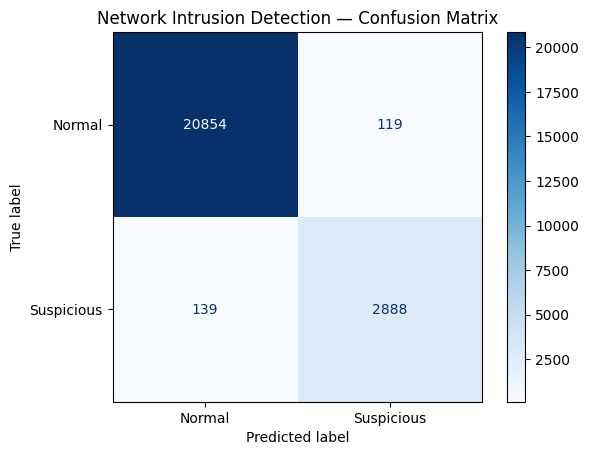

In [ ]:
# Evaluate on the held-out test set. Use these real outputs in your presentation.
y_pred = model.predict(X_test_selected)

metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1-score": f1_score(y_test, y_pred, zero_division=0),
}
display(pd.DataFrame([metrics]).round(4))
print(classification_report(y_test, y_pred, target_names=["Normal", "Suspicious"], zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["Normal", "Suspicious"], cmap="Blues"
)
plt.title("Network Intrusion Detection — Confusion Matrix")
plt.show()


In [ ]:
# Save the trained model bundle to Google Drive for later use.
ARTIFACT_DIR = f"{DATA_DIR}/artifacts"
os.makedirs(ARTIFACT_DIR, exist_ok=True)

bundle = {
    "preprocessor": preprocessor,
    "selected_mask": selected_mask,
    "model": model,
    "input_columns": list(X.columns),
    "label_mapping": {0: "Normal", 1: "Suspicious"}
}
model_path = f"{ARTIFACT_DIR}/unsw_nb15_ga_mlp.joblib"
joblib.dump(bundle, model_path)
print("Saved model to:", model_path)


Saved model to: /content/drive/MyDrive/CSV Files/artifacts/unsw_nb15_ga_mlp.joblib


## Predict on new network traffic

Upload a CSV with the same raw feature columns as the UNSW-NB15 dataset (without requiring `Label`). This cell uses the trained model to predict Normal/Suspicious. Use only data you are authorized to analyze.


In [ ]:
# Optional: set this to a CSV path in Drive to predict on new records.

NEW_CSV = "/content/drive/MyDrive/CSV Files/Training and Testing Sets/UNSW_NB15_testing-set.csv"


if NEW_CSV and os.path.exists(NEW_CSV):
    new_df = pd.read_csv(NEW_CSV, low_memory=False, encoding="latin1")
    new_df.columns = [str(c).strip() for c in new_df.columns]
    new_X = new_df.drop(columns=["Label", "label", "attack_cat", "srcip", "dstip", "Stime", "Ltime"], errors="ignore")
    new_X = new_X.reindex(columns=X.columns, fill_value=np.nan)
    new_encoded = preprocessor.transform(new_X)
    new_encoded = np.nan_to_num(new_encoded, nan=0.0, posinf=0.0, neginf=0.0)
    new_pred = model.predict(new_encoded[:, selected_mask])
    output = pd.DataFrame({
        "prediction": new_pred,
        "classification": np.where(new_pred == 1, "Suspicious", "Normal")
    })
    if hasattr(model, "predict_proba"):
        output["suspicious_probability"] = model.predict_proba(new_encoded[:, selected_mask])[:, 1]
    display(output.head(20))
    output.to_csv(f"{DATA_DIR}/predictions.csv", index=False)
    print("Predictions saved to:", f"{DATA_DIR}/predictions.csv")
else:
    print("Prediction skipped. Set NEW_CSV to a valid CSV path when you have new records.")


,prediction,classification,suspicious_probability
0,1,Suspicious,0.937717
1,1,Suspicious,0.938588
2,1,Suspicious,0.922633
3,1,Suspicious,0.911008
4,1,Suspicious,0.912180
5,1,Suspicious,0.928542
6,1,Suspicious,0.929461
7,1,Suspicious,0.922901
8,0,Normal,0.000003
9,0,Normal,0.000003


Predictions saved to: /content/drive/MyDrive/CSV Files/predictions.csv
